# Student Academic performence Analysis and Prediction

## Import Libraries

In [2]:
import sys
from pathlib import Path

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Dataset Initial Inspection

In [4]:
df = pd.read_csv("/Applications/Coding/3rd_Semester/Classroom/AI ML-1 Lab/Mini_project_1/Student-Academic-Performance-Analysis-and-Prediction/dataset/student_performance.csv")

In [5]:
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [6]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [7]:
df.tail()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


In [8]:
df.shape

(6607, 20)

In [9]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='str')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [11]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


## Data Quality Assessment

In [12]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [13]:
(df.isnull().sum() / len(df)) * 100

Hours_Studied                 0.000000
Attendance                    0.000000
Parental_Involvement          0.000000
Access_to_Resources           0.000000
Extracurricular_Activities    0.000000
Sleep_Hours                   0.000000
Previous_Scores               0.000000
Motivation_Level              0.000000
Internet_Access               0.000000
Tutoring_Sessions             0.000000
Family_Income                 0.000000
Teacher_Quality               1.180566
School_Type                   0.000000
Peer_Influence                0.000000
Physical_Activity             0.000000
Learning_Disabilities         0.000000
Parental_Education_Level      1.362192
Distance_from_Home            1.014076
Gender                        0.000000
Exam_Score                    0.000000
dtype: float64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.nunique()

Hours_Studied                 41
Attendance                    41
Parental_Involvement           3
Access_to_Resources            3
Extracurricular_Activities     2
Sleep_Hours                    7
Previous_Scores               51
Motivation_Level               3
Internet_Access                2
Tutoring_Sessions              9
Family_Income                  3
Teacher_Quality                3
School_Type                    2
Peer_Influence                 3
Physical_Activity              7
Learning_Disabilities          2
Parental_Education_Level       3
Distance_from_Home             3
Gender                         2
Exam_Score                    45
dtype: int64

In [16]:
df.select_dtypes(include='object').columns

/var/folders/ny/tds05q3n08j5hszjd5hjt1wc0000gn/T/ipykernel_2398/3732952691.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['Parental_Involvement', 'Access_to_Resources',
       'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access',
       'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence',
       'Learning_Disabilities', 'Parental_Education_Level',
       'Distance_from_Home', 'Gender'],
      dtype='str')

In [17]:
df.select_dtypes(include=['int64', 'float64']).columns

Index(['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
       'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score'],
      dtype='str')

In [18]:
for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))


Parental_Involvement
Parental_Involvement
Medium    3362
High      1908
Low       1337
Name: count, dtype: int64

Access_to_Resources
Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64

Extracurricular_Activities
Extracurricular_Activities
Yes    3938
No     2669
Name: count, dtype: int64

Motivation_Level
Motivation_Level
Medium    3351
Low       1937
High      1319
Name: count, dtype: int64

Internet_Access
Internet_Access
Yes    6108
No      499
Name: count, dtype: int64

Family_Income
Family_Income
Low       2672
Medium    2666
High      1269
Name: count, dtype: int64

Teacher_Quality
Teacher_Quality
Medium    3925
High      1947
Low        657
Name: count, dtype: int64

School_Type
School_Type
Public     4598
Private    2009
Name: count, dtype: int64

Peer_Influence
Peer_Influence
Positive    2638
Neutral     2592
Negative    1377
Name: count, dtype: int64

Learning_Disabilities
Learning_Disabilities
No     5912
Yes     695
Name: count, dty

/var/folders/ny/tds05q3n08j5hszjd5hjt1wc0000gn/T/ipykernel_2398/3176533357.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


## Data Cleaning & Preprocessing

In [19]:
df_clean = df.copy()

In [20]:
df_clean.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [21]:
numerical_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns

categorical_cols = df_clean.select_dtypes(include='object').columns

/var/folders/ny/tds05q3n08j5hszjd5hjt1wc0000gn/T/ipykernel_2398/3670234236.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(include='object').columns


In [22]:
df_clean.duplicated().sum()

np.int64(0)

In [23]:
df_clean[df_clean.duplicated(keep=False)]

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score


In [24]:
df_clean = df_clean.drop_duplicates()

In [25]:
df_clean.dtypes

Hours_Studied                 int64
Attendance                    int64
Parental_Involvement            str
Access_to_Resources             str
Extracurricular_Activities      str
Sleep_Hours                   int64
Previous_Scores               int64
Motivation_Level                str
Internet_Access                 str
Tutoring_Sessions             int64
Family_Income                   str
Teacher_Quality                 str
School_Type                     str
Peer_Influence                  str
Physical_Activity             int64
Learning_Disabilities           str
Parental_Education_Level        str
Distance_from_Home              str
Gender                          str
Exam_Score                    int64
dtype: object

In [26]:
df_clean.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [27]:
for col in categorical_cols:
    print(f"\n{col}:")
    print(df_clean[col].unique())


Parental_Involvement:
<ArrowStringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

Access_to_Resources:
<ArrowStringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str

Extracurricular_Activities:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Motivation_Level:
<ArrowStringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

Internet_Access:
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

Family_Income:
<ArrowStringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

Teacher_Quality:
<ArrowStringArray>
['Medium', 'High', 'Low', nan]
Length: 4, dtype: str

School_Type:
<ArrowStringArray>
['Public', 'Private']
Length: 2, dtype: str

Peer_Influence:
<ArrowStringArray>
['Positive', 'Negative', 'Neutral']
Length: 3, dtype: str

Learning_Disabilities:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Parental_Education_Level:
<ArrowStringArray>
['High School', 'College', 'Postgraduate', nan]
Length: 4, dtype: str

Distance_from_Home:
<ArrowStringArray>

## Feature Identification & Target Variable Selection

In [28]:
df_clean.columns.tolist()

['Hours_Studied',
 'Attendance',
 'Parental_Involvement',
 'Access_to_Resources',
 'Extracurricular_Activities',
 'Sleep_Hours',
 'Previous_Scores',
 'Motivation_Level',
 'Internet_Access',
 'Tutoring_Sessions',
 'Family_Income',
 'Teacher_Quality',
 'School_Type',
 'Peer_Influence',
 'Physical_Activity',
 'Learning_Disabilities',
 'Parental_Education_Level',
 'Distance_from_Home',
 'Gender',
 'Exam_Score']

In [29]:
'Exam_Score' in df_clean.columns

True

In [30]:
target = 'Exam_Score'

In [31]:
df_clean[target].head()

0    67
1    61
2    74
3    71
4    70
Name: Exam_Score, dtype: int64

In [32]:
df_clean[target].describe()

count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

In [33]:
features = df_clean.drop(columns=[target])

In [34]:
features.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female


In [35]:
X = df_clean.drop(columns=[target])
y = df_clean[target]

In [36]:
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (6607, 19)
Target Shape: (6607,)


In [37]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print(numerical_features)

['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']


In [38]:
categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print(categorical_features)

['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


/var/folders/ny/tds05q3n08j5hszjd5hjt1wc0000gn/T/ipykernel_2398/2028005365.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


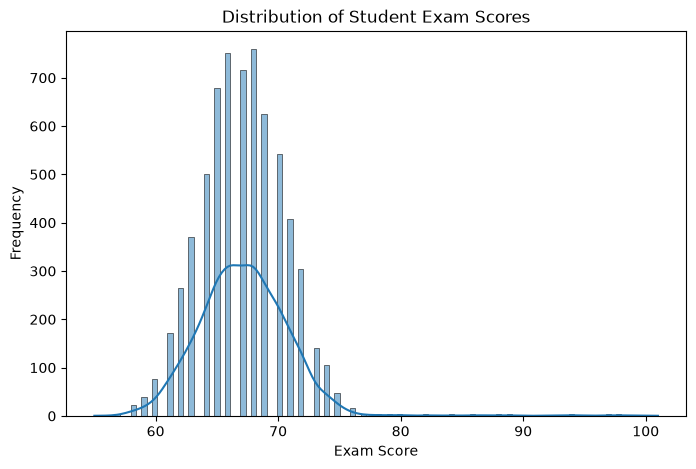

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(y, kde=True)

plt.title('Distribution of Student Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Frequency')

plt.show()

## Exploratory Data Analysis (EDA): Univariate Analysis

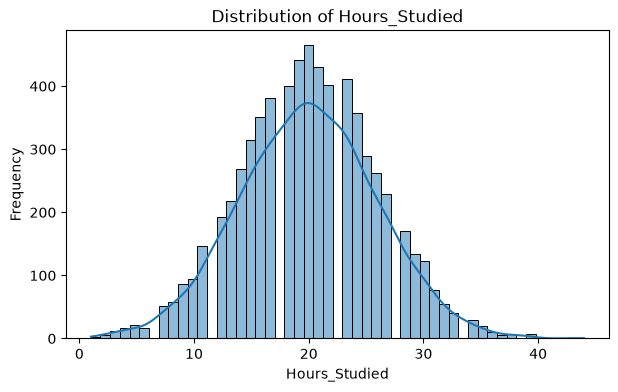

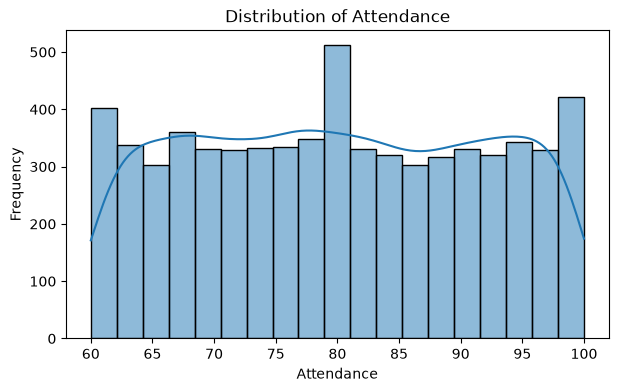

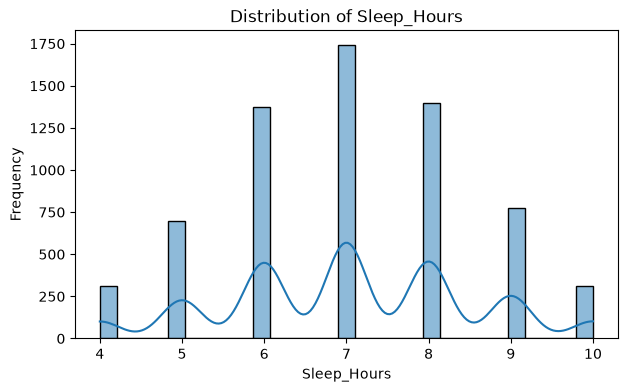

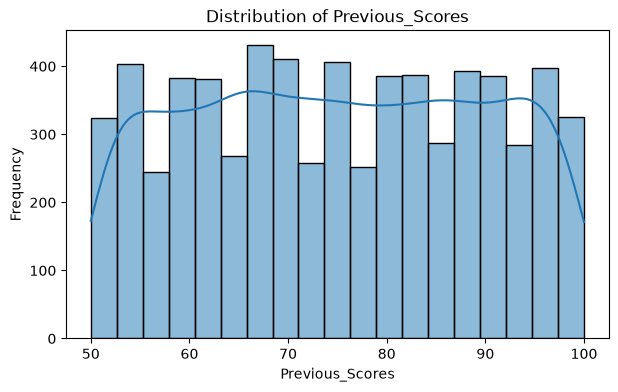

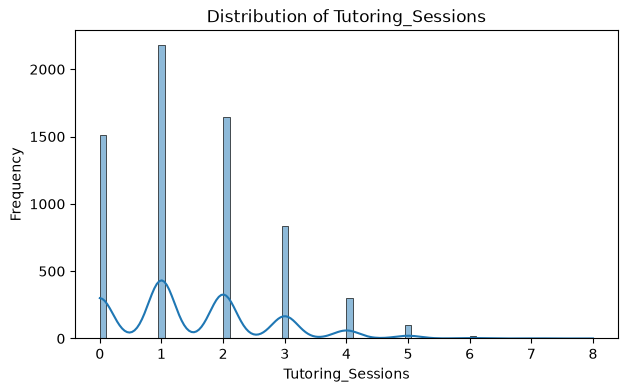

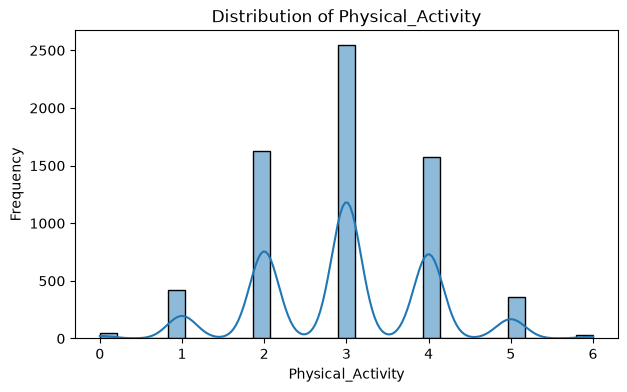

In [40]:

for col in numerical_features:

    plt.figure(figsize=(7, 4))

    sns.histplot(data=df_clean, x=col, kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.show()

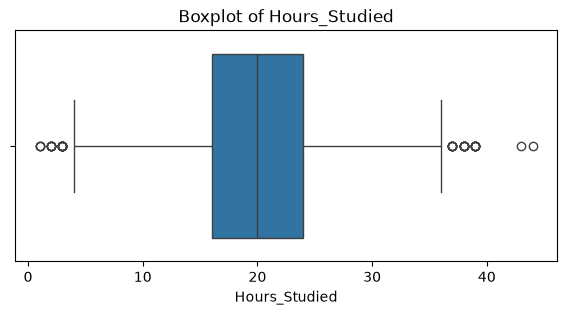

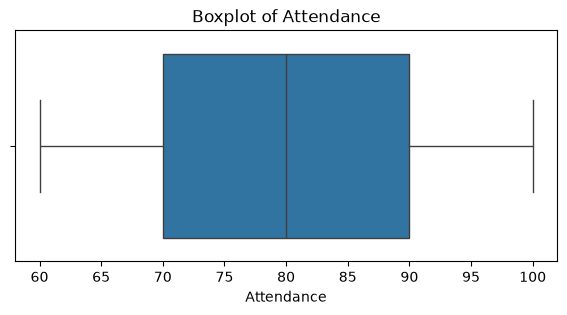

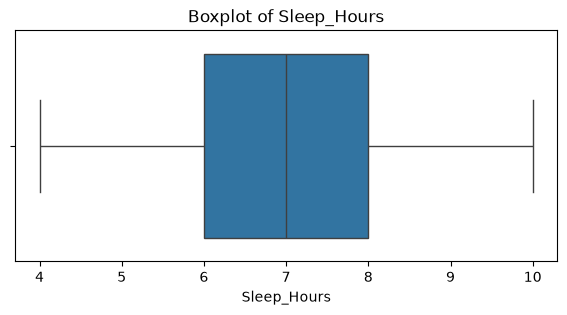

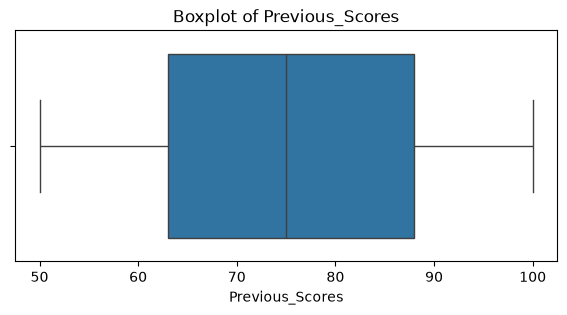

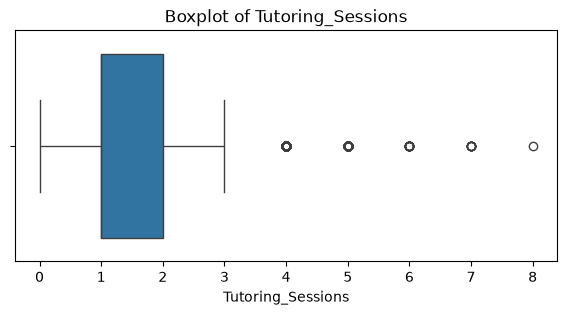

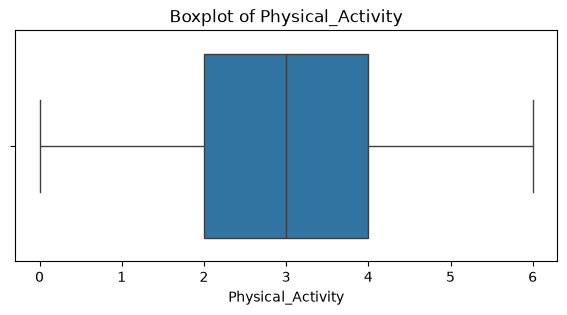

In [41]:
for col in numerical_features:

    plt.figure(figsize=(7, 3))

    sns.boxplot(x=df_clean[col])

    plt.title(f'Boxplot of {col}')

    plt.show()

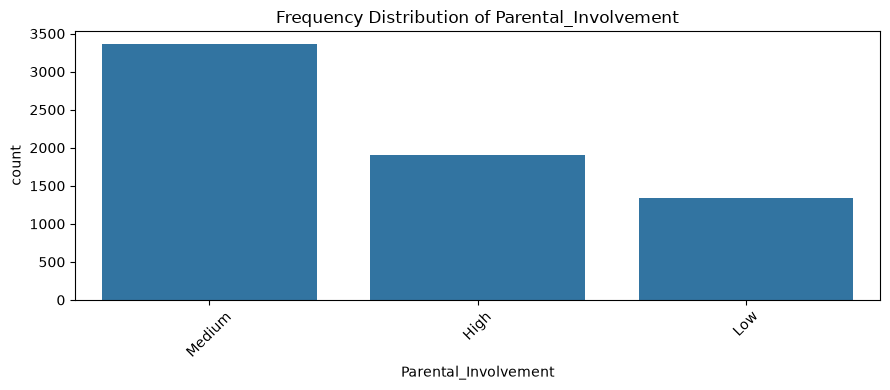

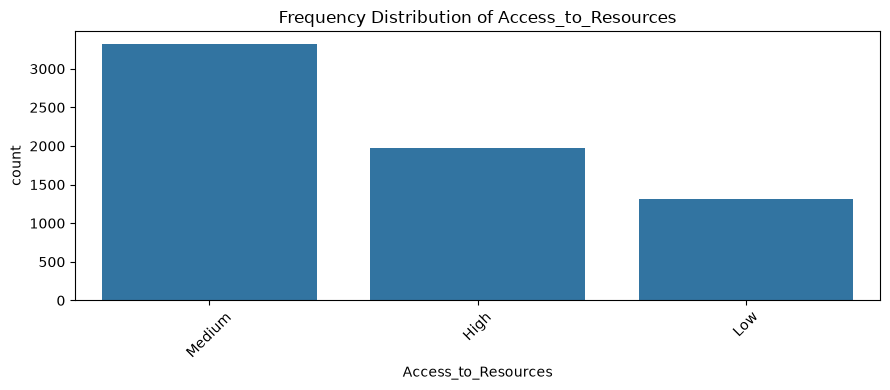

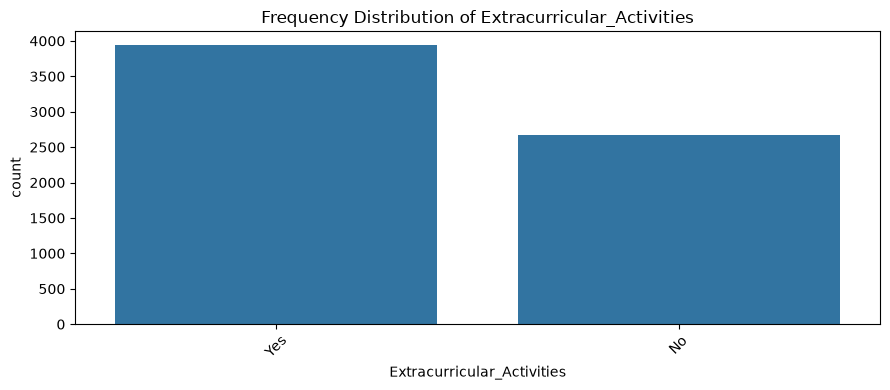

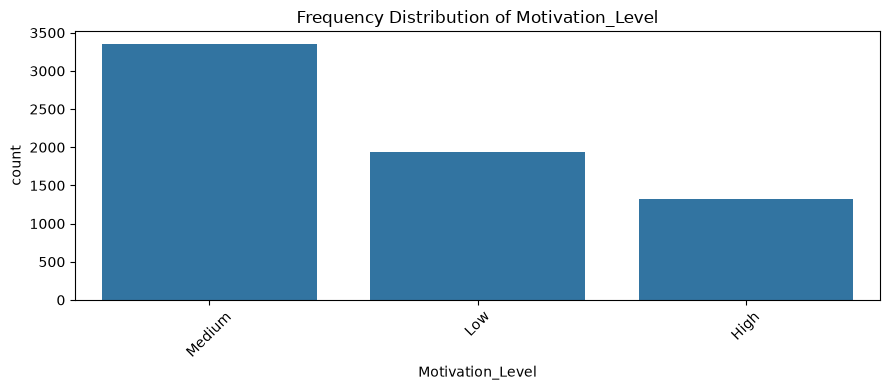

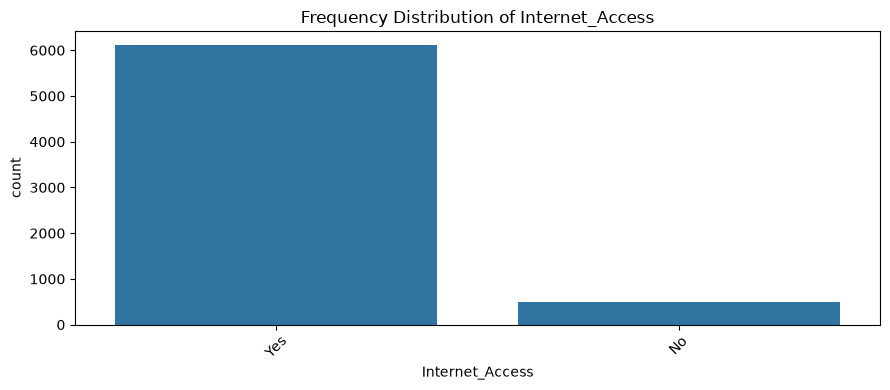

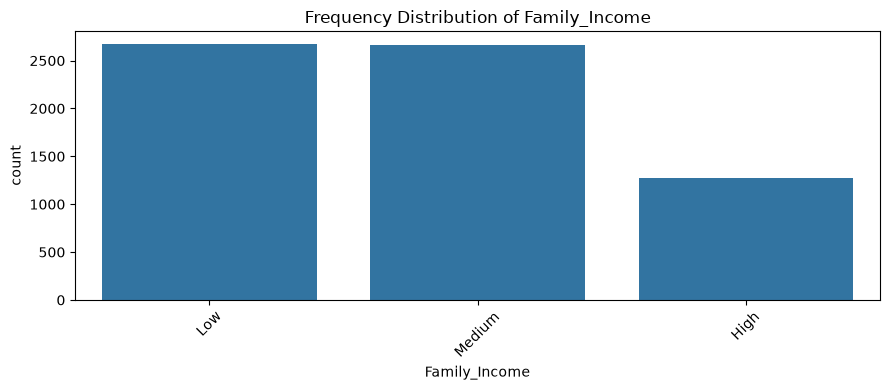

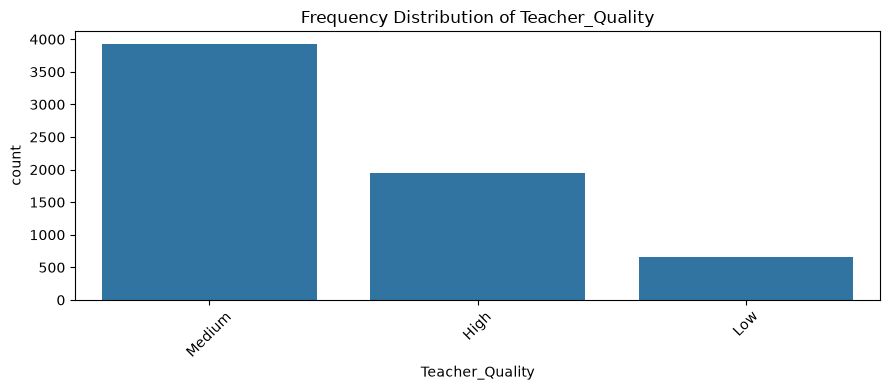

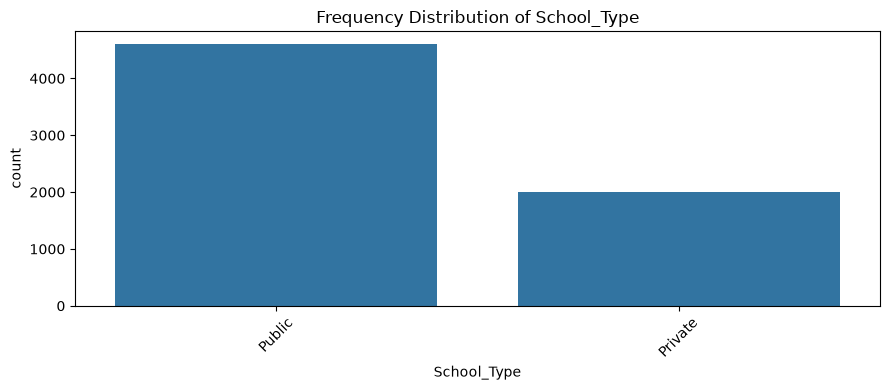

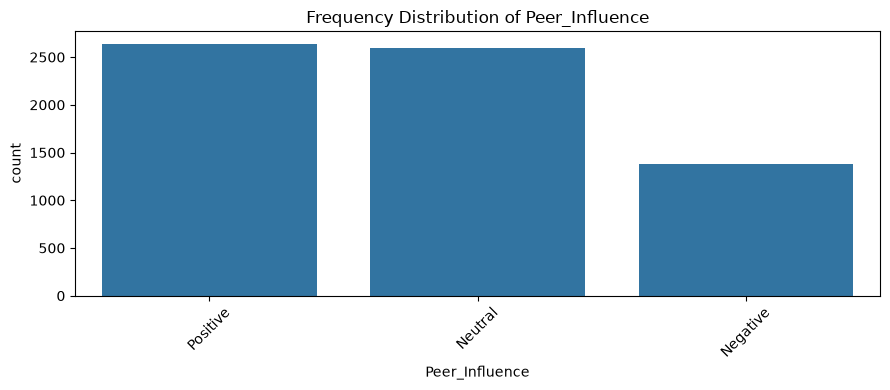

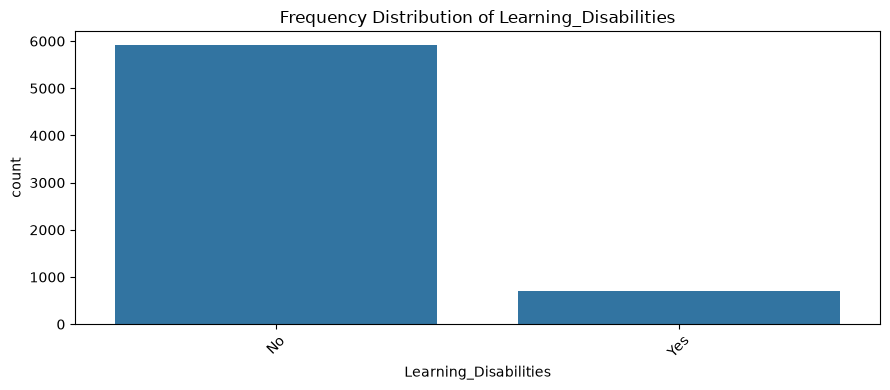

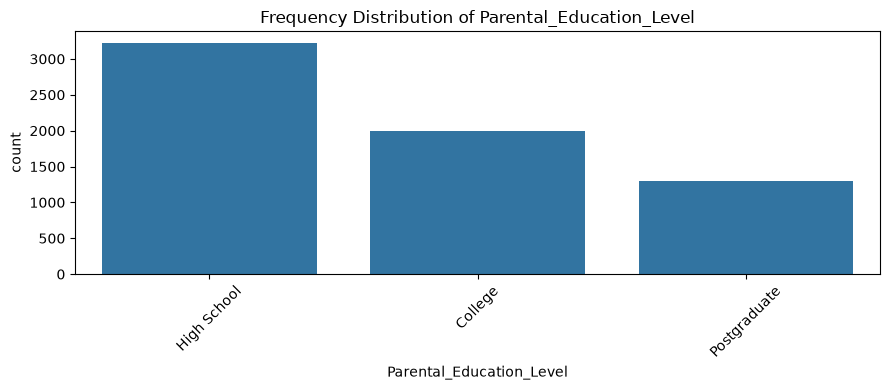

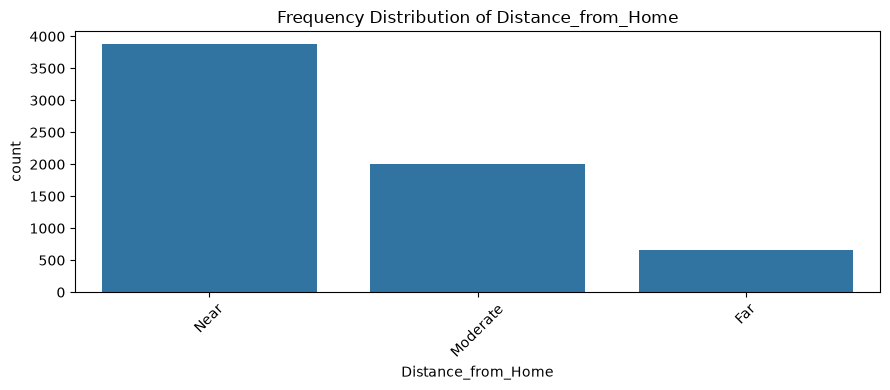

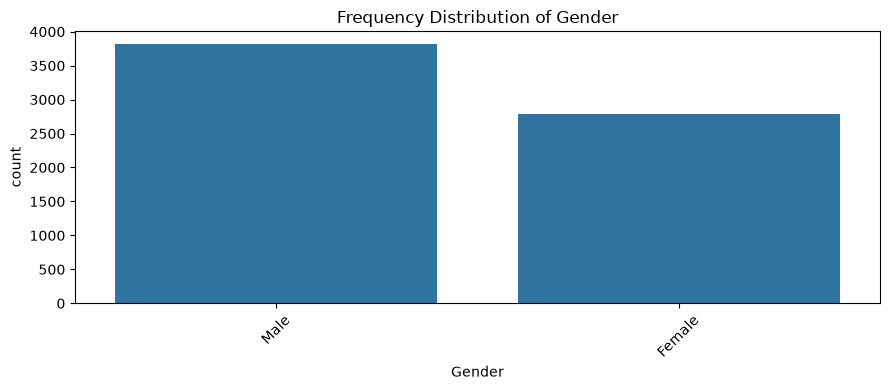

In [42]:
for col in categorical_features:

    plt.figure(figsize=(9, 4))

    sns.countplot(
        data=df_clean,
        x=col,
        order=df_clean[col].value_counts().index
    )

    plt.title(f'Frequency Distribution of {col}')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

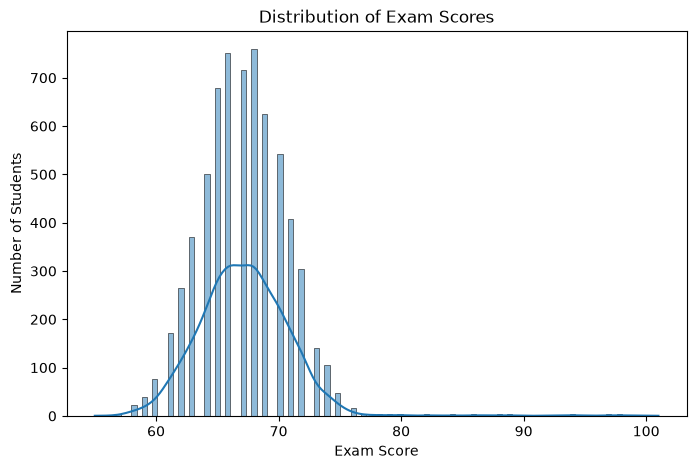

In [43]:
plt.figure(figsize=(8, 5))

sns.histplot(df_clean['Exam_Score'], kde=True)

plt.title('Distribution of Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')

plt.show()

In [44]:
print("Mean:", df_clean['Exam_Score'].mean())
print("Median:", df_clean['Exam_Score'].median())
print("Standard Deviation:", df_clean['Exam_Score'].std())
print("Minimum:", df_clean['Exam_Score'].min())
print("Maximum:", df_clean['Exam_Score'].max())

Mean: 67.23565914938702
Median: 67.0
Standard Deviation: 3.890455781261732
Minimum: 55
Maximum: 101


Observation:
The distribution shows that most students have
exam scores concentrated within a particular range.

## Bivariate Analysis & Correlation Analysis

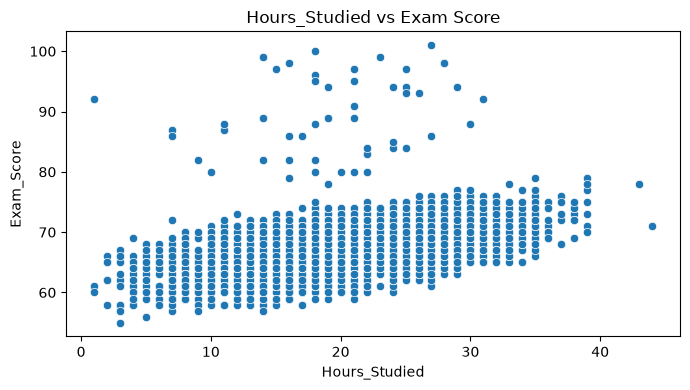

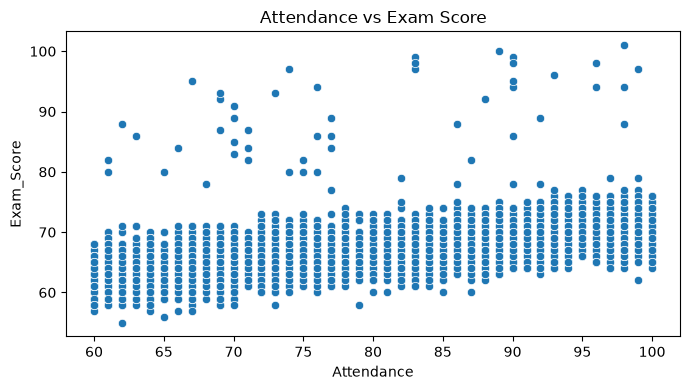

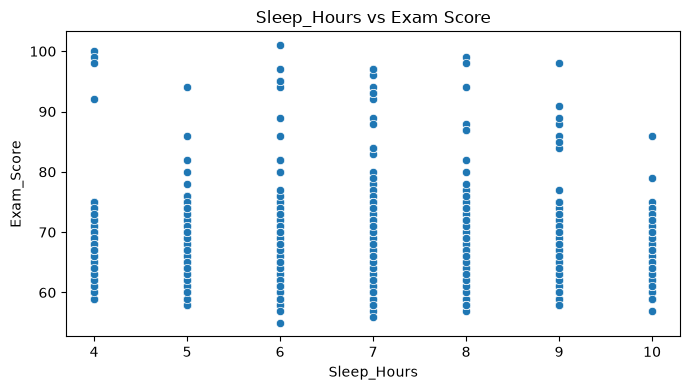

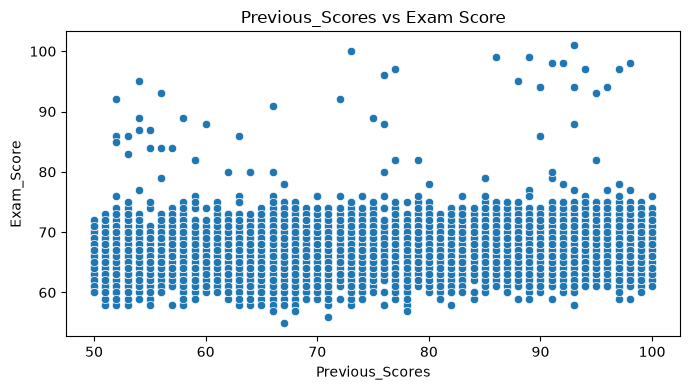

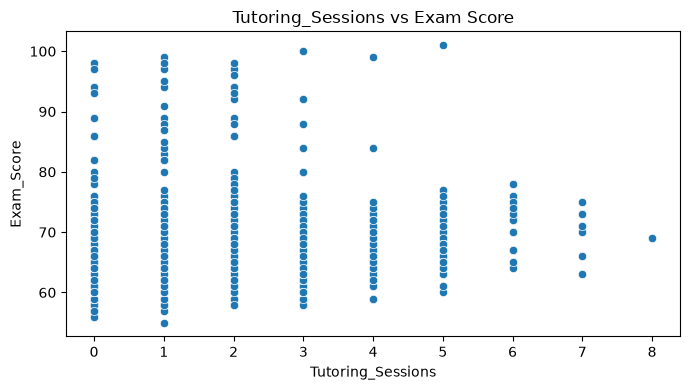

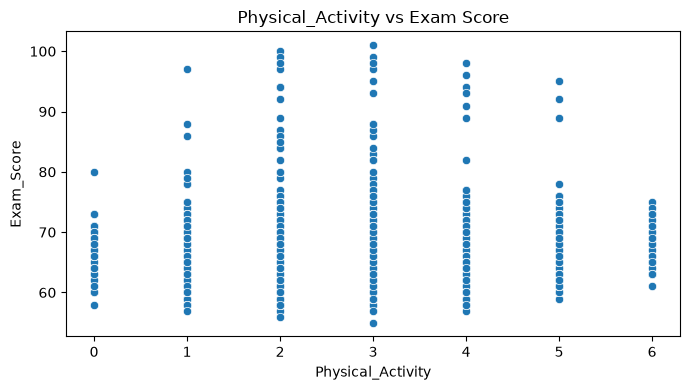

In [45]:
for col in numerical_features:
    if col != 'Exam_Score':

        plt.figure(figsize=(7, 4))

        sns.scatterplot(data=df_clean, x=col, y='Exam_Score')

        plt.title(f'{col} vs Exam Score')
        plt.tight_layout()
        plt.show()

In [46]:
correlation = df_clean.select_dtypes(
    include=['number']
).corr()

correlation

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
Hours_Studied,1.000000,-0.009908,0.010977,0.024846,-0.014282,0.004624,0.445455
Attendance,-0.009908,1.000000,-0.015918,-0.020186,0.014324,-0.022435,0.581072
Sleep_Hours,0.010977,-0.015918,1.000000,-0.021750,-0.012216,-0.000378,-0.017022
Previous_Scores,0.024846,-0.020186,-0.021750,1.000000,-0.013122,-0.011274,0.175079
Tutoring_Sessions,-0.014282,0.014324,-0.012216,-0.013122,1.000000,0.017733,0.156525
Physical_Activity,0.004624,-0.022435,-0.000378,-0.011274,0.017733,1.000000,0.027824
Exam_Score,0.445455,0.581072,-0.017022,0.175079,0.156525,0.027824,1.000000


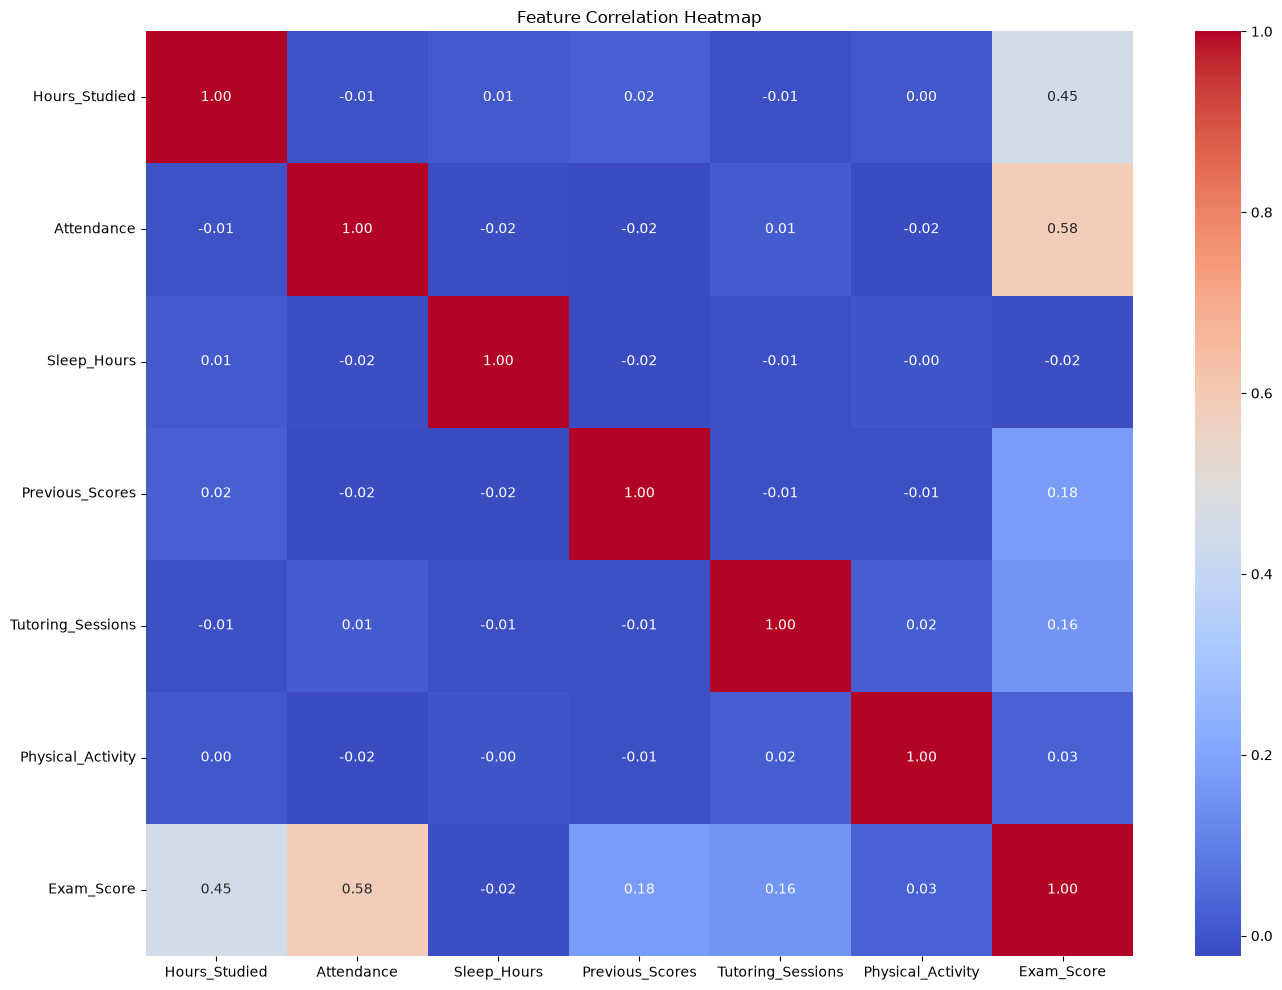

In [47]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [48]:
correlation['Exam_Score'].sort_values(ascending=False)

Exam_Score           1.000000
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64

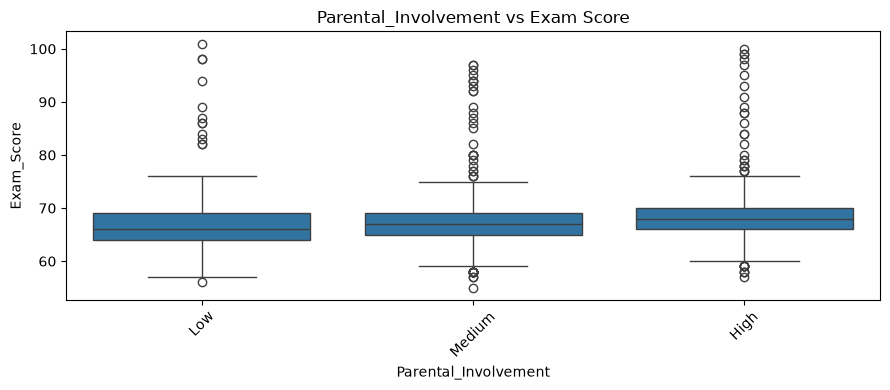

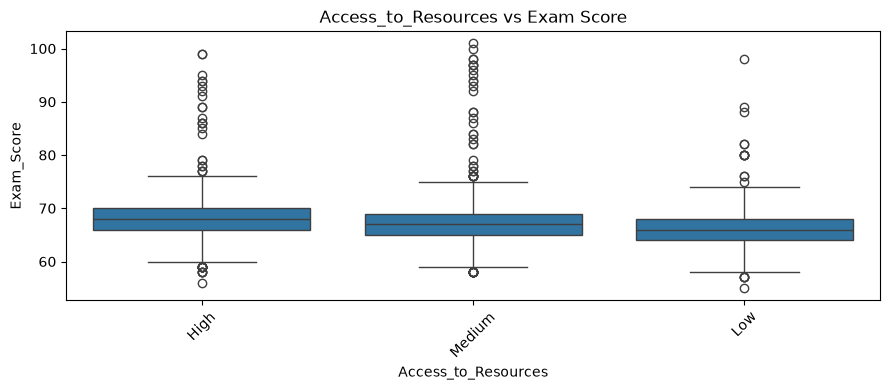

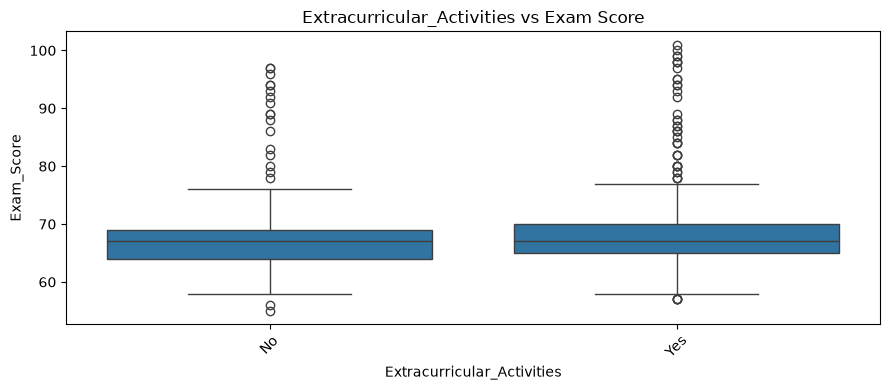

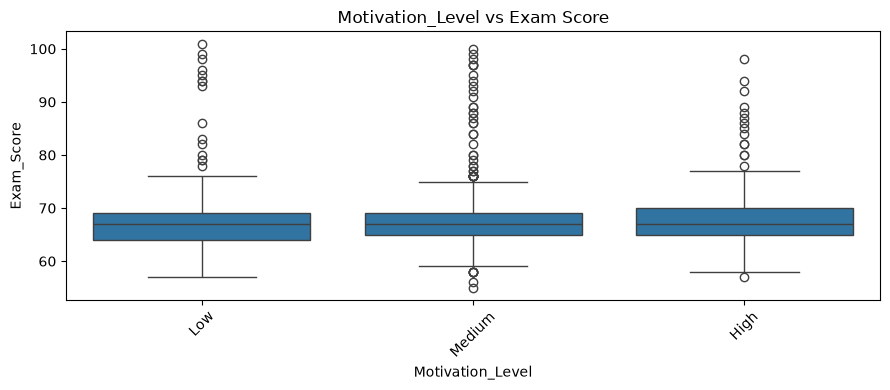

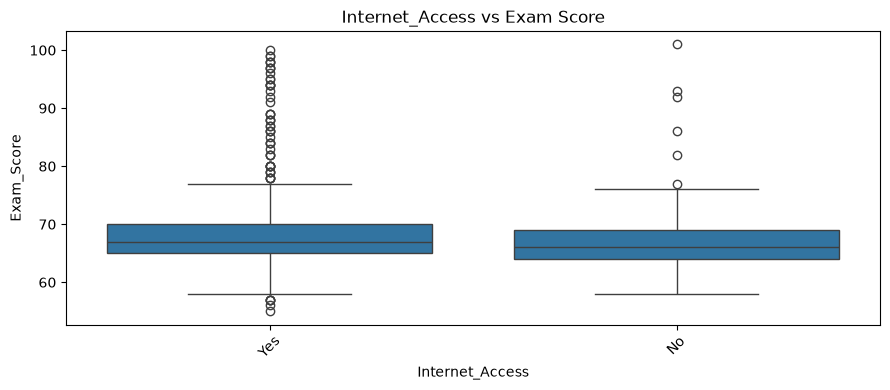

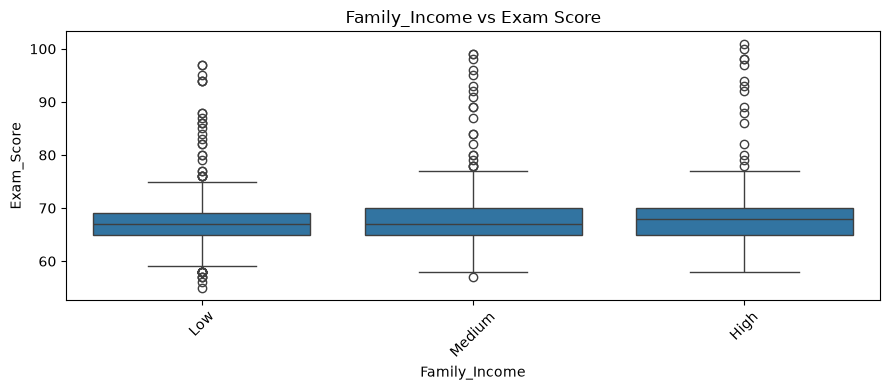

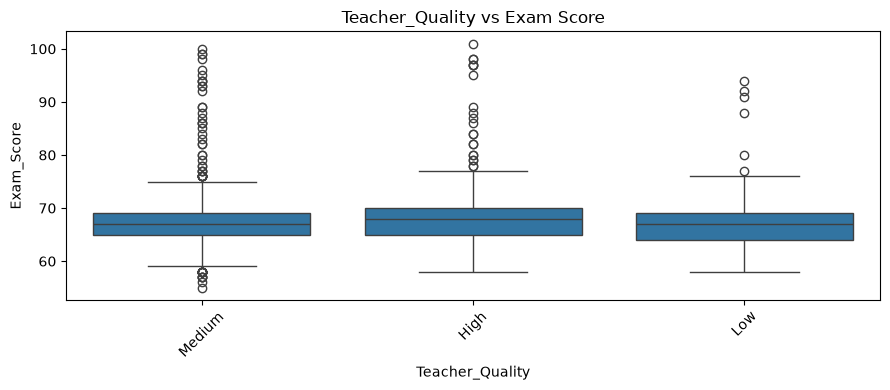

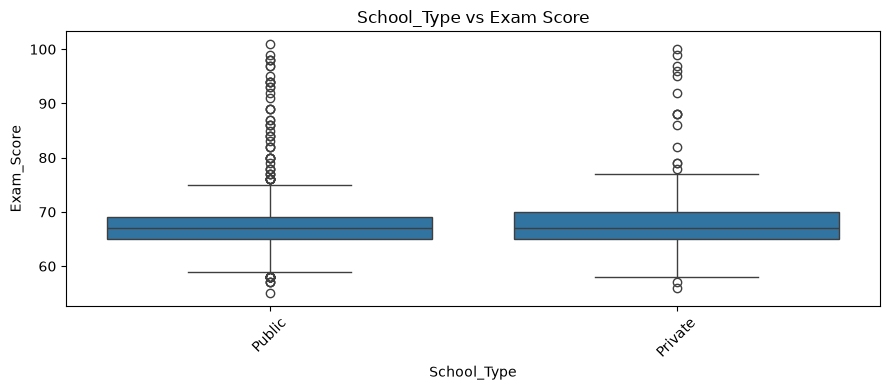

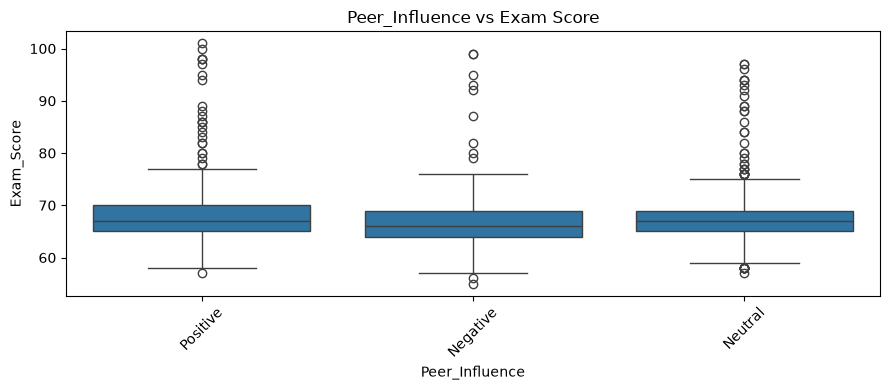

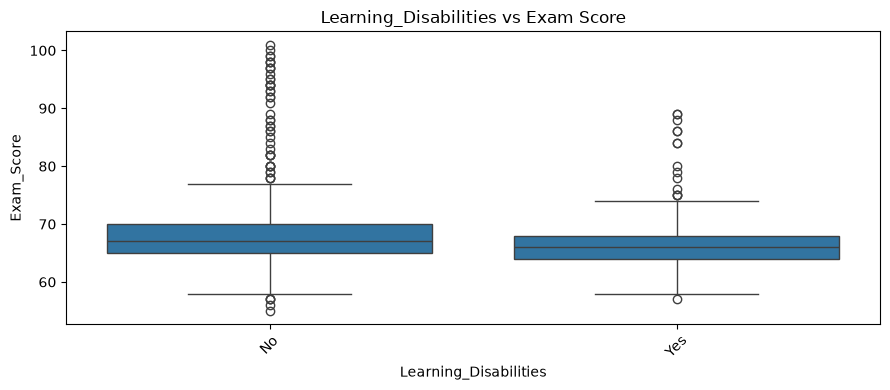

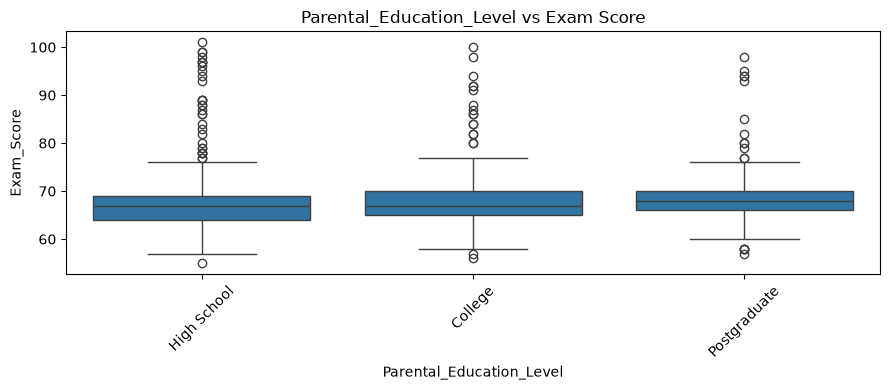

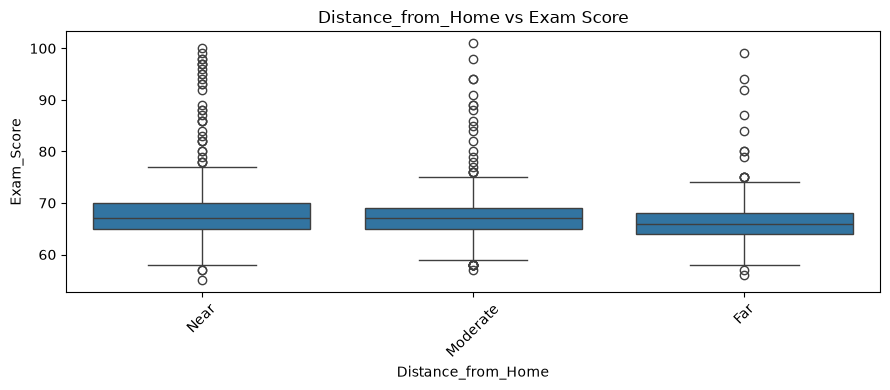

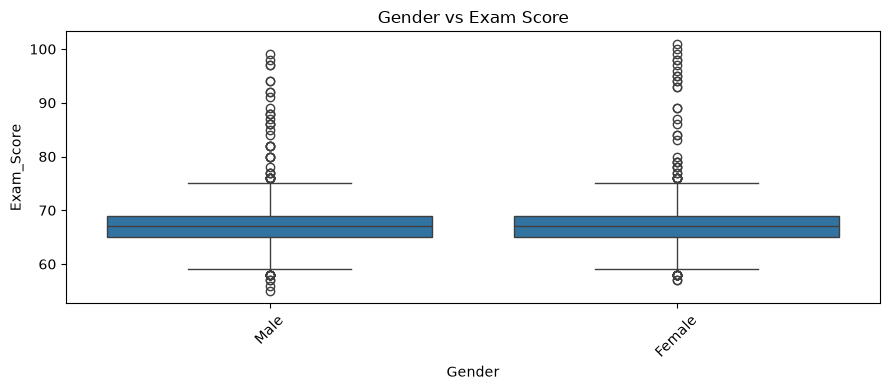

In [49]:
for col in categorical_features:

    plt.figure(figsize=(9, 4))

    sns.boxplot(data=df_clean, x=col, y='Exam_Score')

    plt.title(f'{col} vs Exam Score')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Train-Test Split & Preprocessing Pipeline

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

In [51]:
X = df_clean.drop(columns=['Exam_Score'])
y = df_clean['Exam_Score']

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [53]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

/var/folders/ny/tds05q3n08j5hszjd5hjt1wc0000gn/T/ipykernel_2398/369851143.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [54]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [55]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [56]:
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [57]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [58]:
print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

print("Original Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Original Training Shape: (5285, 19)
Processed Training Shape: (5285, 40)
Original Testing Shape: (1322, 19)
Processed Testing Shape: (1322, 40)


## Simple Linear Regression

In [59]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [60]:
X_simple = df_clean[['Hours_Studied']]
y_simple = df_clean['Exam_Score']

In [61]:
X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

In [62]:
simple_model = LinearRegression()

simple_model.fit(X_train_simple, y_train_simple)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.29]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Hours_Studied']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,61.51
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [63]:
y_pred_simple = simple_model.predict(X_test_simple)

In [64]:
mae = mean_absolute_error(y_test_simple, y_pred_simple)

mse = mean_squared_error(y_test_simple, y_pred_simple)

rmse = np.sqrt(mse)

r2 = r2_score(y_test_simple, y_pred_simple)

print("Simple Linear Regression Results")
print("--------------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Simple Linear Regression Results
--------------------------------
MAE: 2.4475687452945643
MSE: 10.855921288793322
RMSE: 3.294832513010839
R2 Score: 0.2319868674542105


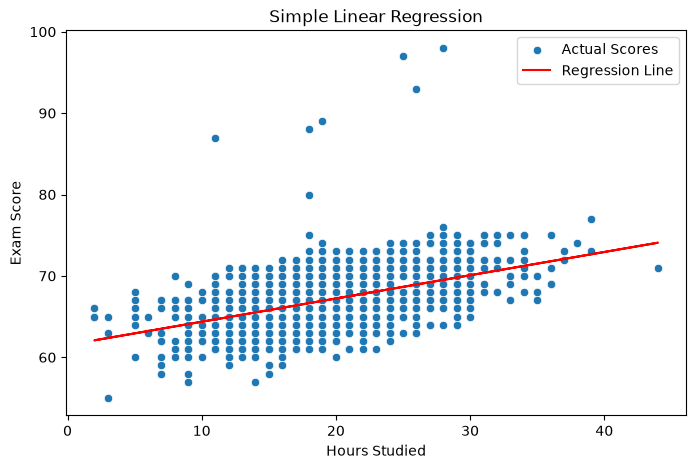

In [65]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_test_simple['Hours_Studied'],
    y=y_test_simple,
    label='Actual Scores'
)

plt.plot(
    X_test_simple['Hours_Studied'],
    y_pred_simple,
    color='red',
    label='Regression Line'
)

plt.title('Simple Linear Regression')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.legend()

plt.show()

In [66]:
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])

Intercept: 61.511167469044246
Coefficient: 0.2856687444430866


## Multiple Linear Regression

In [67]:
from sklearn.linear_model import LinearRegression

multiple_model = LinearRegression()

In [68]:
multiple_model.fit(X_train_processed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](40,)","[ 1.76, 2.29,-0.02,..., 0.46, 0.01,-0.01]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,66.16
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,40
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(27)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](40,)","[74.78,73.84,72.85,..., 0. , 0. , 0. ]"


In [69]:
y_pred_multiple = multiple_model.predict(X_test_processed)

In [70]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_multiple = mean_absolute_error(y_test, y_pred_multiple)

mse_multiple = mean_squared_error(y_test, y_pred_multiple)

rmse_multiple = np.sqrt(mse_multiple)

r2_multiple = r2_score(y_test, y_pred_multiple)

print("Multiple Linear Regression Results")
print("----------------------------------")
print("MAE:", mae_multiple)
print("MSE:", mse_multiple)
print("RMSE:", rmse_multiple)
print("R2 Score:", r2_multiple)

Multiple Linear Regression Results
----------------------------------
MAE: 0.4523920089625994
MSE: 3.2560199870428956
RMSE: 1.8044445092722845
R2 Score: 0.7696495724907311


In [71]:
comparison = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'MAE': [mae, mae_multiple],
    'RMSE': [rmse, rmse_multiple],
    'R2 Score': [r2, r2_multiple]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Simple Linear Regression,2.447569,3.294833,0.231987
1,Multiple Linear Regression,0.452392,1.804445,0.769650


## Polynomial Regression

In [72]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

poly_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear', LinearRegression())
])

poly_model.fit(X_train_simple, y_train_simple)

y_pred_poly = poly_model.predict(X_test_simple)

In [73]:
mae_poly = mean_absolute_error(y_test_simple, y_pred_poly)
mse_poly = mean_squared_error(y_test_simple, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
r2_poly = r2_score(y_test_simple, y_pred_poly)

print("Polynomial Regression Results")
print("MAE:", mae_poly)
print("RMSE:", rmse_poly)
print("R2 Score:", r2_poly)

Polynomial Regression Results
MAE: 2.4447795821288105
RMSE: 3.2931729586684346
R2 Score: 0.23276034442853466


In [74]:
comparison = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression'
    ],
    'MAE': [mae, mae_multiple, mae_poly],
    'RMSE': [rmse, rmse_multiple, rmse_poly],
    'R2 Score': [r2, r2_multiple, r2_poly]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Simple Linear Regression,2.447569,3.294833,0.231987
1,Multiple Linear Regression,0.452392,1.804445,0.769650
2,Polynomial Regression,2.444780,3.293173,0.232760


## Residual Analysis

In [75]:
residuals = y_test - y_pred_multiple

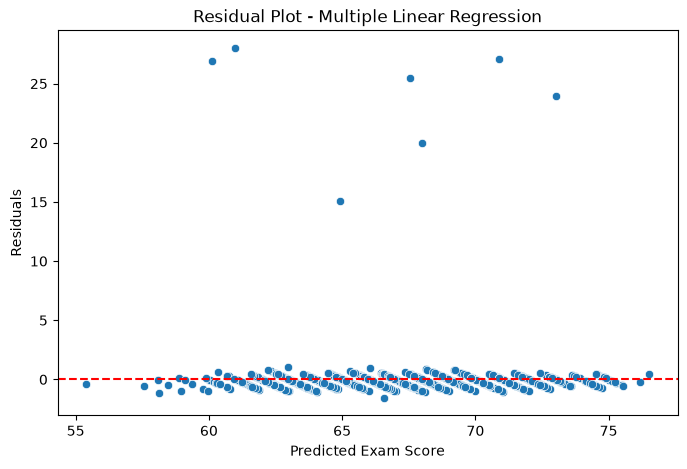

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred_multiple, y=residuals)

plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Exam Score")
plt.ylabel("Residuals")
plt.title("Residual Plot - Multiple Linear Regression")

plt.show()

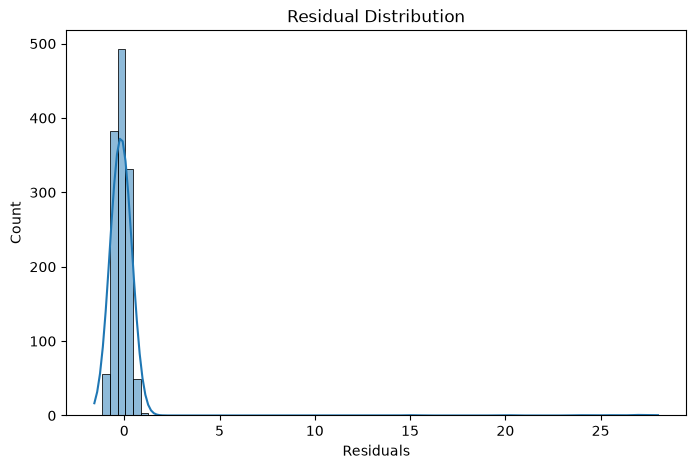

In [77]:
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Residual Distribution")

plt.show()

## Classification — Performance Prediction

In [78]:
def categorize_performance(score):
    if score < 60:
        return 'Low'
    elif score < 80:
        return 'Medium'
    else:
        return 'High'

y_class = y.apply(categorize_performance)

print(y_class.value_counts())

Exam_Score
Medium    6491
Low         68
High        48
Name: count, dtype: int64


In [79]:
from sklearn.model_selection import train_test_split

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X, y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

In [80]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

logistic_model.fit(X_train_cls, y_train_cls)
knn_model.fit(X_train_cls, y_train_cls)

y_pred_logistic = logistic_model.predict(X_test_cls)
y_pred_knn = knn_model.predict(X_test_cls)

In [81]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

for name, predictions in [
    ('Logistic Regression', y_pred_logistic),
    ('KNN', y_pred_knn)
]:
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_test_cls, predictions))
    print("Precision:", precision_score(
        y_test_cls, predictions, average='weighted', zero_division=0
    ))
    print("Recall:", recall_score(
        y_test_cls, predictions, average='weighted', zero_division=0
    ))
    print("F1 Score:", f1_score(
        y_test_cls, predictions, average='weighted', zero_division=0
    ))
    print(classification_report(y_test_cls, predictions, zero_division=0))


Logistic Regression
Accuracy: 0.9909228441754917
Precision: 0.9841980634016139
Recall: 0.9909228441754917
F1 Score: 0.9874036204288174
              precision    recall  f1-score   support

        High       0.00      0.00      0.00         9
         Low       1.00      0.79      0.88        14
      Medium       0.99      1.00      1.00      1299

    accuracy                           0.99      1322
   macro avg       0.66      0.60      0.63      1322
weighted avg       0.98      0.99      0.99      1322


KNN
Accuracy: 0.983358547655068
Precision: 0.976827828365482
Recall: 0.983358547655068
F1 Score: 0.9757632625407567
              precision    recall  f1-score   support

        High       0.00      0.00      0.00         9
         Low       1.00      0.07      0.13        14
      Medium       0.98      1.00      0.99      1299

    accuracy                           0.98      1322
   macro avg       0.66      0.36      0.37      1322
weighted avg       0.98      0.98      0

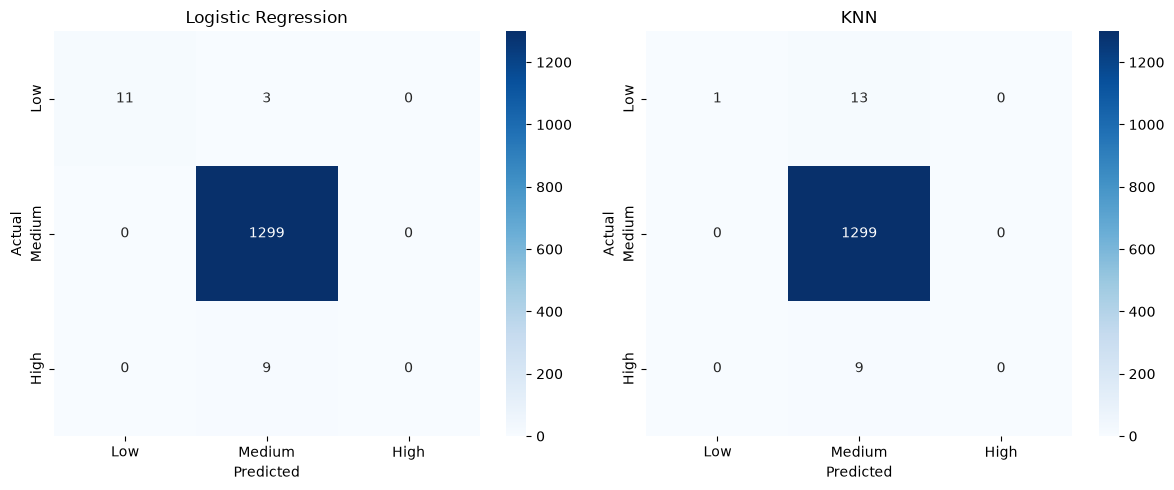

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name, predictions in [
    (axes[0], 'Logistic Regression', y_pred_logistic),
    (axes[1], 'KNN', y_pred_knn)
]:
    cm = confusion_matrix(
        y_test_cls, predictions, labels=['Low', 'Medium', 'High']
    )
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=['Low', 'Medium', 'High'],
        yticklabels=['Low', 'Medium', 'High'],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Model Validation — 5-Fold Cross Validation

In [83]:
from sklearn.model_selection import cross_val_score

In [84]:
reg_cv_scores = cross_val_score(
    multiple_model,
    X_train_processed,
    y_train,
    cv=5,
    scoring='r2'
)

print("Regression CV Scores:", reg_cv_scores)
print("Mean R2 Score:", reg_cv_scores.mean())

Regression CV Scores: [0.79251866 0.81040724 0.74029085 0.70970706 0.56304289]
Mean R2 Score: 0.7231933407844309


In [85]:
logistic_cv_scores = cross_val_score(
    logistic_model,
    X_train_cls,
    y_train_cls,
    cv=5,
    scoring='accuracy'
)

knn_cv_scores = cross_val_score(
    knn_model,
    X_train_cls,
    y_train_cls,
    cv=5,
    scoring='accuracy'
)

print("Logistic Regression CV:", logistic_cv_scores)
print("Logistic Mean Accuracy:", logistic_cv_scores.mean())

print("\nKNN CV:", knn_cv_scores)
print("KNN Mean Accuracy:", knn_cv_scores.mean())

Logistic Regression CV: [0.99148534 0.99053926 0.98959319 0.98580889 0.98864711]
Logistic Mean Accuracy: 0.9892147587511826

KNN CV: [0.98391675 0.9820246  0.9820246  0.9820246  0.98297067]
KNN Mean Accuracy: 0.9825922421948914


In [86]:
cv_comparison = pd.DataFrame({
    'Model': [
        'Multiple Linear Regression',
        'Logistic Regression',
        'KNN'
    ],
    'Mean CV Score': [
        reg_cv_scores.mean(),
        logistic_cv_scores.mean(),
        knn_cv_scores.mean()
    ]
})

cv_comparison

,Model,Mean CV Score
0,Multiple Linear Regression,0.723193
1,Logistic Regression,0.989215
2,KNN,0.982592


## PCA — Dimensionality Reduction

In [87]:
from sklearn.decomposition import PCA

X_train_pca_input = preprocessor.transform(X_train)
X_test_pca_input = preprocessor.transform(X_test)

In [88]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_pca_input)
X_test_pca = pca.transform(X_test_pca_input)

print("Original Features:", X_train_pca_input.shape[1])
print("PCA Features:", X_train_pca.shape[1])
print("Explained Variance:", pca.explained_variance_ratio_.sum())

Original Features: 40
PCA Features: 23
Explained Variance: 0.9523210800220865


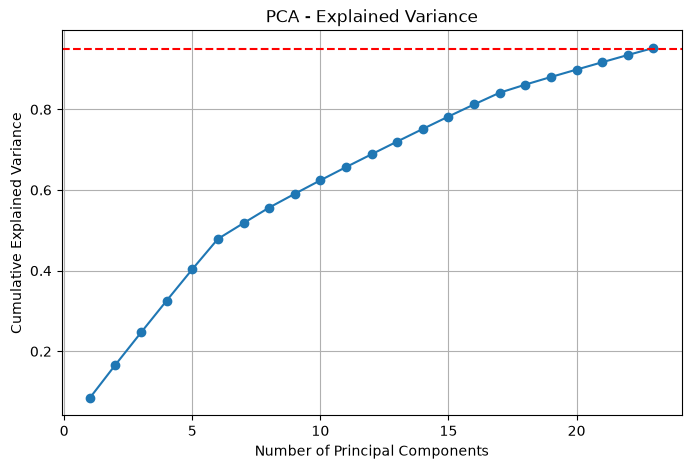

In [89]:
import matplotlib.pyplot as plt
import numpy as np

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1),
         cumulative_variance, marker='o')

plt.axhline(y=0.95, color='red', linestyle='--')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.grid()
plt.show()

In [90]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

pca_model = LinearRegression()

pca_model.fit(X_train_pca, y_train)

y_pred_pca = pca_model.predict(X_test_pca)

print("PCA Regression Results")
print("MAE:", mean_absolute_error(y_test, y_pred_pca))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_pca)))
print("R2 Score:", r2_score(y_test, y_pred_pca))

PCA Regression Results
MAE: 0.5928078208067452
RMSE: 1.8644067030509728
R2 Score: 0.7540859899369202


In [91]:
pca_comparison = pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'PCA Regression'],
    'R2 Score': [
        r2_score(y_test, y_pred_multiple),
        r2_score(y_test, y_pred_pca)
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_multiple),
        mean_absolute_error(y_test, y_pred_pca)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_multiple)),
        np.sqrt(mean_squared_error(y_test, y_pred_pca))
    ]
})

pca_comparison

,Model,R2 Score,MAE,RMSE
0,Multiple Linear Regression,0.769650,0.452392,1.804445
1,PCA Regression,0.754086,0.592808,1.864407


## Advanced Machine Learning Models

In [92]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

In [93]:
models = {
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
    'SVR': SVR(kernel='rbf')
}

predictions = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    predictions[name] = model.predict(X_test_processed)

In [94]:
results = []

for name, y_pred in predictions.items():
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2 Score': r2_score(y_test, y_pred)
    })

advanced_comparison = pd.DataFrame(results)

advanced_comparison

,Model,MAE,RMSE,R2 Score
0,Decision Tree,1.748865,3.539062,0.113909
1,Random Forest,1.079228,2.155993,0.671151
2,SVR,0.486969,1.828585,0.763445


In [95]:
all_models_comparison = pd.concat(
    [comparison, advanced_comparison],
    ignore_index=True
)

all_models_comparison.sort_values(
    by='R2 Score', ascending=False
)

,Model,MAE,RMSE,R2 Score
1,Multiple Linear Regression,0.452392,1.804445,0.769650
5,SVR,0.486969,1.828585,0.763445
4,Random Forest,1.079228,2.155993,0.671151
2,Polynomial Regression,2.444780,3.293173,0.232760
0,Simple Linear Regression,2.447569,3.294833,0.231987
3,Decision Tree,1.748865,3.539062,0.113909


## Unsupervised Learning — Clustering & Anomaly Detection

In [96]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

X_cluster = preprocessor.fit_transform(X)

# Convert to dense array if sparse
if hasattr(X_cluster, "toarray"):
    X_cluster = X_cluster.toarray()

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_cluster)

df_cluster = df_clean.copy()
df_cluster['Cluster'] = clusters

df_cluster[['Exam_Score', 'Cluster']].head()

,Exam_Score,Cluster
0,67,2
1,61,0
2,74,2
3,71,2
4,70,1


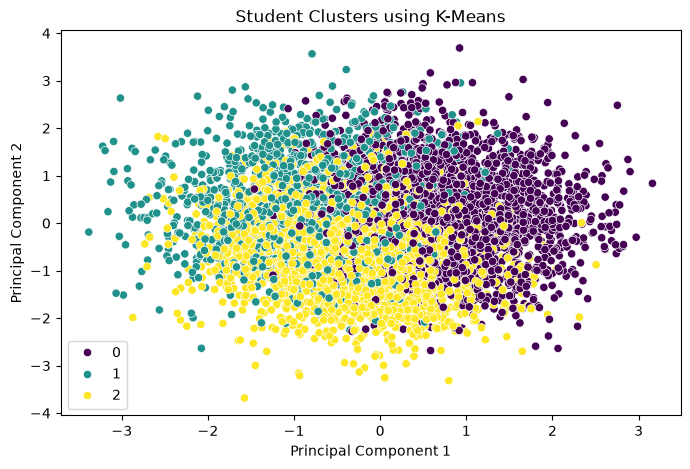

In [97]:
pca_cluster = PCA(n_components=2)

X_cluster_2d = pca_cluster.fit_transform(X_cluster)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_cluster_2d[:, 0],
    y=X_cluster_2d[:, 1],
    hue=clusters,
    palette='viridis'
)

plt.title("Student Clusters using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [98]:
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(
    contamination=0.05,
    random_state=42
)

anomaly_labels = iso_forest.fit_predict(X_cluster)

df_cluster['Anomaly'] = anomaly_labels

print("Normal Records:", (anomaly_labels == 1).sum())
print("Anomalies:", (anomaly_labels == -1).sum())

Normal Records: 6276
Anomalies: 331


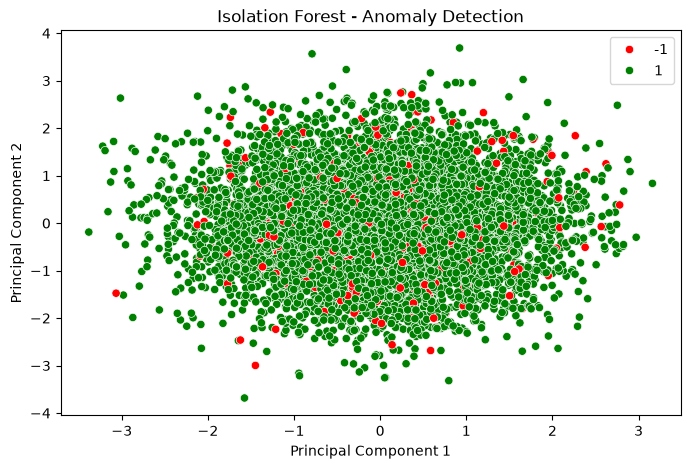

In [99]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_cluster_2d[:, 0],
    y=X_cluster_2d[:, 1],
    hue=anomaly_labels,
    palette={1: 'green', -1: 'red'}
)

plt.title("Isolation Forest - Anomaly Detection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

## Hierarchical Clustering + Association Rule Mining

In [100]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_model = AgglomerativeClustering(n_clusters=3)

# Use the existing PCA coordinates
hierarchical_clusters = hierarchical_model.fit_predict(X_cluster_2d)

df_cluster['Hierarchical_Cluster'] = hierarchical_clusters

print(df_cluster['Hierarchical_Cluster'].value_counts())

Hierarchical_Cluster
0    2882
1    2461
2    1264
Name: count, dtype: int64


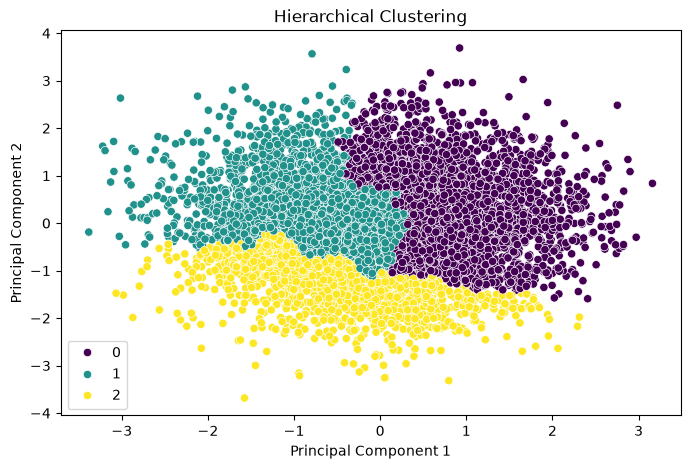

In [101]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_cluster_2d[:, 0],
    y=X_cluster_2d[:, 1],
    hue=hierarchical_clusters,
    palette='viridis'
)

plt.title("Hierarchical Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [102]:
from mlxtend.frequent_patterns import apriori, association_rules

# Convert categorical features into transactions
association_data = df_clean.drop(columns=['Exam_Score']).copy()

# Bin numerical columns
numeric_cols = association_data.select_dtypes(include=np.number).columns

for col in numeric_cols:
    association_data[col] = pd.cut(
        association_data[col],
        bins=3,
        labels=['Low', 'Medium', 'High']
    )

# Convert values into categorical transactions
association_data = association_data.astype(str)
association_data = pd.get_dummies(association_data, dtype=bool)

# Find frequent itemsets
frequent_items = apriori(
    association_data,
    min_support=0.05,
    use_colnames=True
)

# Generate association rules
rules = association_rules(
    frequent_items,
    metric='confidence',
    min_threshold=0.5
)

rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10)

,antecedents,consequents,support,confidence,lift
0,frozenset({Hours_Studied_High}),frozenset({Internet_Access_Yes}),0.053277,0.936170,1.012652
1,frozenset({Hours_Studied_High}),frozenset({Learning_Disabilities_No}),0.051612,0.906915,1.013530
2,frozenset({Hours_Studied_Low}),frozenset({Parental_Involvement_Medium}),0.116392,0.510963,1.004145
3,frozenset({Hours_Studied_Low}),frozenset({Access_to_Resources_Medium}),0.116846,0.512957,1.021123
4,frozenset({Hours_Studied_Low}),frozenset({Extracurricular_Activities_Yes}),0.136371,0.598671,1.004424
5,frozenset({Hours_Studied_Low}),frozenset({Motivation_Level_Medium}),0.114273,0.501661,0.989100
6,frozenset({Hours_Studied_Low}),frozenset({Internet_Access_Yes}),0.209172,0.918272,0.993292
7,frozenset({Hours_Studied_Low}),frozenset({Tutoring_Sessions_Low}),0.183896,0.807309,0.998669
8,frozenset({Hours_Studied_Low}),frozenset({Teacher_Quality_Medium}),0.136371,0.598671,1.007750
9,frozenset({Hours_Studied_Low}),frozenset({School_Type_Public}),0.159074,0.698339,1.003463


## Project Results, Visualization & Report

In [103]:
final_results = pd.concat(
    [comparison, advanced_comparison, pca_comparison],
    ignore_index=True
)

final_results = final_results.drop_duplicates(subset='Model')

final_results = final_results.sort_values(
    by='R2 Score', ascending=False
)

final_results

,Model,MAE,RMSE,R2 Score
1,Multiple Linear Regression,0.452392,1.804445,0.769650
5,SVR,0.486969,1.828585,0.763445
7,PCA Regression,0.592808,1.864407,0.754086
4,Random Forest,1.079228,2.155993,0.671151
2,Polynomial Regression,2.444780,3.293173,0.232760
0,Simple Linear Regression,2.447569,3.294833,0.231987
3,Decision Tree,1.748865,3.539062,0.113909


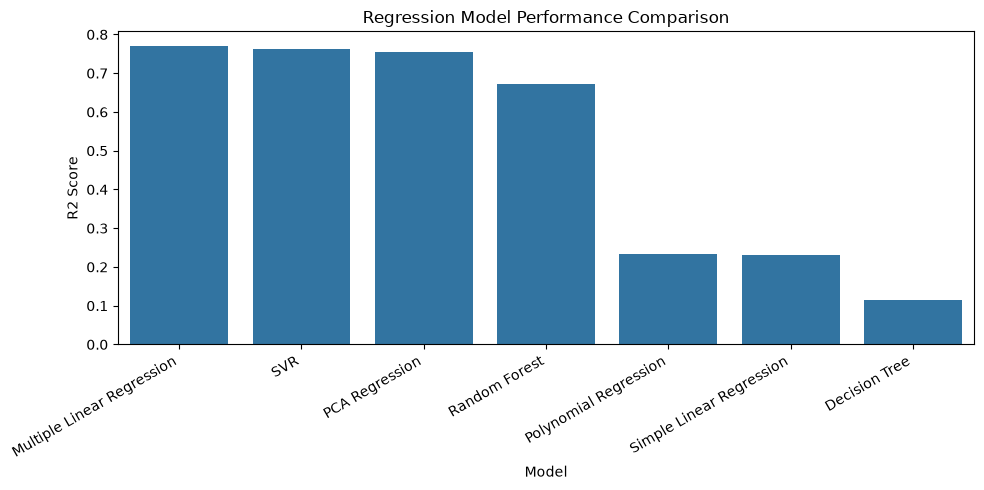

In [104]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=final_results,
    x='Model',
    y='R2 Score'
)

plt.title("Regression Model Performance Comparison")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [105]:
rf_model = models['Random Forest']

feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

feature_importance.head(10)

,Feature,Importance
1,num__Attendance,0.375375
0,num__Hours_Studied,0.239336
3,num__Previous_Scores,0.083233
4,num__Tutoring_Sessions,0.032399
5,num__Physical_Activity,0.024904
2,num__Sleep_Hours,0.024841
9,cat__Access_to_Resources_High,0.018933
6,cat__Parental_Involvement_High,0.017589
7,cat__Parental_Involvement_Low,0.014610
19,cat__Family_Income_High,0.010834


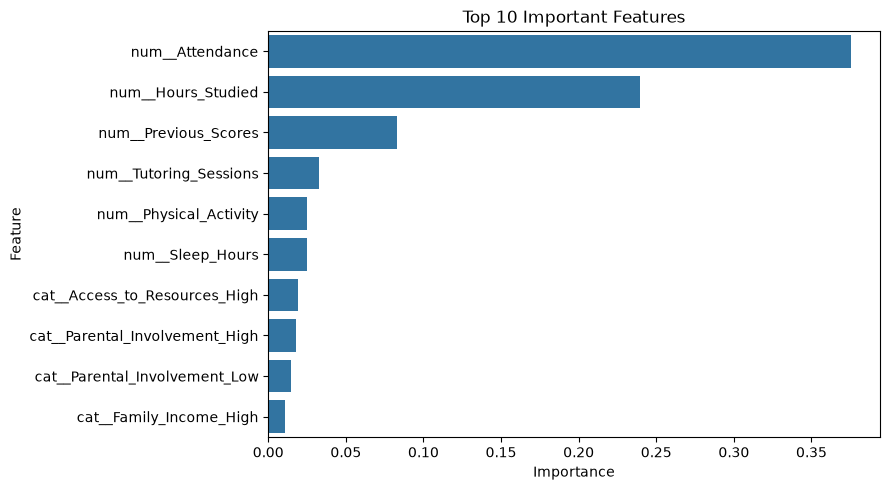

In [106]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features")
plt.tight_layout()
plt.show()